# M6 — Probability Calibration for the ECG Beat Review and Annotation Assistant

**Purpose:** calibrate the selected M2 Version A Random Forest probabilities using sigmoid (Platt) and isotonic calibration, inspect per-class reliability curves, and derive training-only low-confidence thresholds.

**Selected base model:** M2 Version A — the same 17 features (12 REFERENCE_MODEL morphology features + 5 RR_FEATURES), RandomForestClassifier with 200 trees, `max_features="log2"`, `class_weight=None`, `random_state=42`.

**Nested evaluation:** the saved M0 person-grouped 5-fold / 5-repeat assignments are the outer folds. For each outer fold, M2's saved OOF probabilities provide predictions for the held-out people. Four inner models are fitted only on the other four outer-training folds, one inner fold at a time, to create calibration-training OOF predictions. Sigmoid/isotonic maps and per-class confidence thresholds are fit only on those outer-training predictions and labels. The calibrated maps and thresholds are then applied to the untouched outer fold.

**Important:** the target precision used to derive confidence thresholds is a configurable project policy (`TARGET_HIGH_CONFIDENCE_PRECISION`, provisionally 0.80). It is not a clinical threshold. Review and approve it before using it in the app. Classes without enough training support to meet the target are conservatively flagged for review.

This phase evaluates probability reliability. It does not change the selected classifier or the M2 feature set. Do not treat calibration as evidence of diagnostic validity.

## Required Kaggle inputs

Attach these inputs:

**M0 / M1**
- `MITBIH_MLII_DualLead_Dataset_corrected.csv`
- `validated_reconstructed_beat_table.csv.gz` (or `.csv`)
- `m0_row_fold_membership.csv.gz` (or `.csv`)
- `m0_person_fold_membership.csv`
- `m0_split_fingerprint.txt`

**M2 Version A**
- `m2_rr_features_with_sample_positions.csv.gz` (or `.csv`)
- `m2_oof_predictions_REFERENCE_MODEL_PLUS_RR_FEATURES.csv.gz` (or `.csv`)

The M2 Version A OOF prediction file is mandatory. Do not attach the Version B RR table. Duplicate copies of a required filename cause the notebook to stop rather than silently selecting one.

## Run instructions

1. Run once with `RUN_M6_CALIBRATION = False`; all data, split, M2-feature and M2-OOF checks should pass.
2. Set `RUN_M6_CALIBRATION = True` and use **Save Version → Save & Run All (Commit)**.
3. The notebook checkpoints each outer fold. If a Kaggle session stops, rerunning with the same inputs and settings reuses complete fold files.
4. Download `/kaggle/working/ECG_Project/08_M6_PROBABILITY_CALIBRATION/`.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform
import sys
import time
import warnings

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)

# Keep False for the first validation-only run.
RUN_M6_CALIBRATION = True

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/ECG_Project/08_M6_PROBABILITY_CALIBRATION")
FOLD_OUTPUT_DIR = OUTPUT_DIR / "fold_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FOLD_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_ORDER = ["N", "S", "V", "F", "Q"]
FOUR_CLASS_ORDER = ["N", "S", "V", "Q"]
PROB_COLS = [f"Prob_{c}" for c in CLASS_ORDER]
EXPECTED_COUNTS = {"N": 90341, "S": 2781, "V": 7229, "F": 802, "Q": 3894}
EXPECTED_BEATS = 105047
EXPECTED_RECORDS = 46
EXPECTED_PEOPLE = 45

N_SPLITS = 5
N_REPEATS = 5
SEED = 42
TREES = 200
MAX_FEATURES = "log2"
BOOTSTRAP_SAMPLES = 1000
BOOTSTRAP_SEED = 20261105
N_CALIBRATION_BINS = 10

# Project-policy setting for the app's review flag. This is not a clinical value.
TARGET_HIGH_CONFIDENCE_PRECISION = 0.80
MIN_THRESHOLD_SUPPORT = 30
THRESHOLD_GRID = np.round(np.arange(0.05, 1.001, 0.01), 2)

EXPECTED_SPLIT_FINGERPRINT = "5a07f73452ca78af0b212db5e9f060fc4fcc66f49374c2462249189b847440d9"
SIGNAL_COLS = [f"MLII_{i}" for i in range(201)] + [f"Lead2_{i}" for i in range(201)]
AAMI_MAP = {
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
    "A": "S", "a": "S", "J": "S", "S": "S",
    "V": "V", "E": "V", "F": "F", "/": "Q", "f": "Q", "Q": "Q",
}
RR_FEATURES = [
    "pre_RR", "post_RR", "mean_previous_10_RR",
    "pre_RR_div_mean_previous_10_RR", "post_RR_div_pre_RR",
]
EXPECTED_RR_MISSING = {
    "pre_RR": 716,
    "post_RR": 719,
    "mean_previous_10_RR": 259,
    "pre_RR_div_mean_previous_10_RR": 946,
    "post_RR_div_pre_RR": 1385,
}
EXPECTED_ROWS_WITH_MISSING_RR = 1614
BASELINE_NAME = "M2_VERSION_A_REFERENCE_PLUS_RR"
EXPERIMENTS = {
    "M2_UNCALIBRATED": "uncalibrated",
    "M6_SIGMOID": "sigmoid",
    "M6_ISOTONIC": "isotonic",
}

print("PHASE M6 — PROBABILITY CALIBRATION")
print("Training enabled:", RUN_M6_CALIBRATION)
print("Output folder:", OUTPUT_DIR)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| Pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("Base model: Random Forest", TREES, "trees | max_features:", MAX_FEATURES, "| class_weight=None | random_state:", SEED)
print("Calibration methods: sigmoid and isotonic")
print("Threshold policy: target predicted-class precision", TARGET_HIGH_CONFIDENCE_PRECISION,
      "| minimum training support:", MIN_THRESHOLD_SUPPORT)

PHASE M6 — PROBABILITY CALIBRATION
Training enabled: True
Output folder: /kaggle/working/ECG_Project/08_M6_PROBABILITY_CALIBRATION
Python: 3.13.18 | NumPy: 2.1.3 | Pandas: 2.3.3 | scikit-learn: 1.6.1
Base model: Random Forest 200 trees | max_features: log2 | class_weight=None | random_state: 42
Calibration methods: sigmoid and isotonic
Threshold policy: target predicted-class precision 0.8 | minimum training support: 30


In [2]:
def find_one(filename_options):
    matches = []
    for filename in filename_options:
        matches.extend(p for p in INPUT_ROOT.rglob(filename) if p.is_file())
    matches = sorted(set(matches))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one matching file from {filename_options}. Found {len(matches)}:\n"
            + "\n".join(str(p) for p in matches)
        )
    print("FOUND:", matches[0])
    return matches[0]


def atomic_csv(df, path, **kwargs):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    df.to_csv(tmp, **kwargs)
    os.replace(tmp, path)


def validate_probability_matrix(prob, name):
    prob = np.asarray(prob, dtype=float)
    if prob.ndim != 2 or prob.shape[1] != len(CLASS_ORDER):
        raise ValueError(f"{name}: expected probability matrix with 5 columns, got {prob.shape}.")
    if not np.isfinite(prob).all():
        raise ValueError(f"{name}: non-finite probabilities found.")
    if (prob < -1e-7).any() or (prob > 1.0 + 1e-7).any():
        raise ValueError(f"{name}: probability outside [0, 1].")
    if not np.allclose(prob.sum(axis=1), 1.0, atol=1e-5):
        raise ValueError(f"{name}: probability rows do not sum to one.")


def validate_oof(df, name, truth_df, expected_fold_df):
    required = ["Repeat", "Fold", "Row_Index", "Record_ID", "Person_ID", "True_Label", "Predicted_Label"] + PROB_COLS
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"{name}: missing columns {missing}.")
    out = df.copy()
    for col in ["Repeat", "Fold", "Row_Index", "Record_ID"]:
        out[col] = pd.to_numeric(out[col], errors="raise").astype(int)
    for col in ["Person_ID", "True_Label", "Predicted_Label"]:
        out[col] = out[col].astype(str).str.strip()
    if len(out) != EXPECTED_BEATS * N_REPEATS:
        raise ValueError(f"{name}: expected {EXPECTED_BEATS * N_REPEATS} rows, found {len(out)}.")
    if out.duplicated(["Repeat", "Row_Index"]).any():
        raise ValueError(f"{name}: duplicate (Repeat, Row_Index) predictions.")
    chk = out.merge(truth_df, on="Row_Index", how="left", validate="many_to_one", suffixes=("", "_truth"))
    if chk["AAMI_Label"].isna().any():
        raise ValueError(f"{name}: unknown Row_Index values.")
    for left, right in [("Record_ID", "Record_ID_truth"), ("Person_ID", "Person_ID_truth"), ("True_Label", "AAMI_Label")]:
        if not (chk[left].astype(str) == chk[right].astype(str)).all():
            raise ValueError(f"{name}: {left} does not align with the corrected dataset.")
    fold_chk = out.merge(expected_fold_df, on=["Repeat", "Row_Index"], how="left", validate="one_to_one")
    if fold_chk["Expected_Fold"].isna().any() or not (fold_chk["Fold"] == fold_chk["Expected_Fold"]).all():
        raise ValueError(f"{name}: predictions do not use the locked M0 fold assignments.")
    validate_probability_matrix(out[PROB_COLS].to_numpy(dtype=float), name)
    return out

## 1. Load and verify the corrected M0/M1 data

In [3]:
corrected_path = find_one(["MITBIH_MLII_DualLead_Dataset_corrected.csv"])
beat_table_path = find_one(["validated_reconstructed_beat_table.csv.gz", "validated_reconstructed_beat_table.csv"])

DATA = pd.read_csv(corrected_path, low_memory=False)
DATA.columns = [str(c).strip().strip('"').strip("'").strip() for c in DATA.columns]
if DATA.shape != (106870, 404):
    raise ValueError(f"Unexpected corrected dataset shape: {DATA.shape}.")
if any(c not in DATA.columns for c in SIGNAL_COLS):
    raise ValueError("Corrected dataset is missing one or more waveform columns.")
DATA["Record_ID"] = pd.to_numeric(DATA["Record_ID"], errors="raise").astype(int)
DATA["Label"] = DATA["Label"].astype(str).str.strip()
DATA["AAMI_Label"] = DATA["Label"].map(AAMI_MAP)
aami_df = DATA[DATA["AAMI_Label"].isin(CLASS_ORDER)].copy().reset_index(drop=True)
aami_df["Person_ID"] = ["person_201_202" if rid in (201, 202) else f"person_{rid}" for rid in aami_df["Record_ID"].to_numpy()]
aami_df["Row_Index"] = np.arange(len(aami_df), dtype=np.int64)

counts = aami_df["AAMI_Label"].value_counts().reindex(CLASS_ORDER, fill_value=0).to_dict()
assert len(aami_df) == EXPECTED_BEATS, len(aami_df)
assert aami_df["Record_ID"].nunique() == EXPECTED_RECORDS
assert aami_df["Person_ID"].nunique() == EXPECTED_PEOPLE
assert counts == EXPECTED_COUNTS, counts
assert np.isfinite(aami_df[SIGNAL_COLS].to_numpy(dtype=np.float32)).all()

beat_table = pd.read_csv(beat_table_path, compression="infer", low_memory=False)
beat_table.columns = [str(c).strip().strip('"').strip("'").strip() for c in beat_table.columns]
required_m1 = ["Record_ID", "Person_ID", "Sample_Index", "Original_Symbol", "AAMI_Label"] + SIGNAL_COLS
missing_m1 = [c for c in required_m1 if c not in beat_table.columns]
if missing_m1:
    raise ValueError(f"M1 beat table is missing columns: {missing_m1[:15]}.")
beat_table["Record_ID"] = pd.to_numeric(beat_table["Record_ID"], errors="raise").astype(int)
beat_table["Sample_Index"] = pd.to_numeric(beat_table["Sample_Index"], errors="raise").astype(np.int64)
for col in ["Person_ID", "AAMI_Label", "Original_Symbol"]:
    beat_table[col] = beat_table[col].astype(str).str.strip()
if len(beat_table) != EXPECTED_BEATS or beat_table[["Record_ID", "Sample_Index"]].duplicated().any():
    raise ValueError("M1 beat-table row count or composite-key uniqueness is invalid.")
for col in ["Record_ID", "Person_ID", "AAMI_Label"]:
    if not np.array_equal(beat_table[col].to_numpy(), aami_df[col].to_numpy()):
        raise ValueError(f"M1 {col} does not match the corrected dataset row-by-row.")
processed = aami_df[SIGNAL_COLS].to_numpy(dtype=np.float32)
reconstructed = beat_table[SIGNAL_COLS].to_numpy(dtype=np.float32)
if not np.array_equal(processed, reconstructed):
    mismatch = np.argwhere(processed != reconstructed)
    raise ValueError(f"M1 waveform mismatch. First mismatch: {mismatch[0].tolist()}.")
aami_df["Sample_Index"] = beat_table["Sample_Index"].to_numpy(dtype=np.int64)
aami_df["Original_Symbol"] = beat_table["Original_Symbol"].to_numpy()

print("CORRECTED DATA AND M1 POSITIONS — PASS")
print("Valid beats:", len(aami_df), "| Records:", aami_df.Record_ID.nunique(), "| People:", aami_df.Person_ID.nunique())
print("Class counts:", counts, "| 402 waveform values match row-by-row: PASS")

FOUND: /kaggle/input/datasets/aakashshah3799/ecg-arrhythmia-project-corrected-v1/MITBIH_MLII_DualLead_Dataset_corrected.csv
FOUND: /kaggle/input/datasets/aakashshah3799/ecg-arrhythmia-project-corrected-v1/validated_reconstructed_beat_table.csv
CORRECTED DATA AND M1 POSITIONS — PASS
Valid beats: 105047 | Records: 46 | People: 45
Class counts: {'N': 90341, 'S': 2781, 'V': 7229, 'F': 802, 'Q': 3894} | 402 waveform values match row-by-row: PASS


## 2. Restore and verify the locked M0 splits

In [4]:
row_path = find_one(["m0_row_fold_membership.csv.gz", "m0_row_fold_membership.csv"])
person_path = find_one(["m0_person_fold_membership.csv"])
fingerprint_path = find_one(["m0_split_fingerprint.txt"])
row_fold = pd.read_csv(row_path, compression="infer")
person_fold = pd.read_csv(person_path)
for col in ["Row_Index", "Repeat", "Fold"]:
    row_fold[col] = pd.to_numeric(row_fold[col], errors="raise").astype(int)
for col in ["Repeat", "Fold"]:
    person_fold[col] = pd.to_numeric(person_fold[col], errors="raise").astype(int)
person_fold["Person_ID"] = person_fold["Person_ID"].astype(str).str.strip()
computed_fp = hashlib.sha256(
    person_fold.sort_values(["Repeat", "Person_ID"]).to_csv(index=False, lineterminator="\n").encode("utf-8")
).hexdigest()
saved_fp = fingerprint_path.read_text().strip()
assert saved_fp == EXPECTED_SPLIT_FINGERPRINT
assert computed_fp == EXPECTED_SPLIT_FINGERPRINT
assert len(row_fold) == EXPECTED_BEATS * N_REPEATS
assert len(person_fold) == EXPECTED_PEOPLE * N_REPEATS
assert not row_fold.duplicated(["Repeat", "Row_Index"]).any()
assert not person_fold.duplicated(["Repeat", "Person_ID"]).any()
assert set(row_fold["Row_Index"]) == set(aami_df["Row_Index"])
assert set(person_fold["Person_ID"]) == set(aami_df["Person_ID"])
row_to_person = aami_df.set_index("Row_Index")["Person_ID"]
row_fold["Person_ID"] = row_fold["Row_Index"].map(row_to_person)
if row_fold["Person_ID"].isna().any():
    raise ValueError("Some saved Row_Index values have no Person_ID mapping.")
joined = row_fold.merge(person_fold, on=["Repeat", "Person_ID"], suffixes=("_row", "_person"), how="left", validate="many_to_one")
if joined["Fold_person"].isna().any() or not (joined["Fold_row"] == joined["Fold_person"]).all():
    raise ValueError("Saved row-level and person-level fold assignments disagree.")
row_to_position = {int(r): i for i, r in enumerate(aami_df["Row_Index"].to_numpy())}
row_fold["Position"] = row_fold["Row_Index"].map(row_to_position).astype(int)
fold_assignment_by_repeat = {}
for repeat in range(1, N_REPEATS + 1):
    current = row_fold[row_fold["Repeat"] == repeat]
    assignment = np.full(EXPECTED_BEATS, -1, dtype=np.int8)
    assignment[current["Position"].to_numpy()] = current["Fold"].to_numpy()
    if not np.isin(assignment, [1, 2, 3, 4, 5]).all():
        raise ValueError(f"Incomplete saved fold assignments in repeat {repeat}.")
    if current.groupby("Person_ID")["Fold"].nunique().max() != 1:
        raise ValueError(f"Person leakage in repeat {repeat}.")
    rec_check = current.merge(aami_df[["Row_Index", "Record_ID"]], on="Row_Index", validate="many_to_one")
    if rec_check.groupby("Record_ID")["Fold"].nunique().max() != 1:
        raise ValueError(f"Record leakage in repeat {repeat}.")
    fold_assignment_by_repeat[repeat] = assignment

expected_fold_df = row_fold[["Repeat", "Row_Index", "Fold"]].rename(columns={"Fold": "Expected_Fold"})
print("ORIGINAL M0 SPLITS RESTORED — PASS")
print("Split fingerprint:", computed_fp)
print("New splits generated: NO")

FOUND: /kaggle/input/datasets/aakashshah3799/ecg-arrhythmia-project-corrected-v1/m0_row_fold_membership.csv
FOUND: /kaggle/input/datasets/aakashshah3799/ecg-arrhythmia-project-corrected-v1/m0_person_fold_membership.csv
FOUND: /kaggle/input/datasets/aakashshah3799/ecg-arrhythmia-project-corrected-v1/m0_split_fingerprint.txt
ORIGINAL M0 SPLITS RESTORED — PASS
Split fingerprint: 5a07f73452ca78af0b212db5e9f060fc4fcc66f49374c2462249189b847440d9
New splits generated: NO


## 3. Load and verify the selected M2 Version A RR table and OOF predictions

The saved M2 OOF file is used for the outer held-out probabilities. It is not used to fit the calibrator for its own outer fold. Calibration fitting uses new inner OOF predictions generated only from the outer-training people.

In [5]:
rr_path = find_one(["m2_rr_features_with_sample_positions.csv.gz", "m2_rr_features_with_sample_positions.csv"])
rr_table = pd.read_csv(rr_path, compression="infer", low_memory=False)
rr_required = ["Row_Index", "Record_ID", "Person_ID", "Sample_Index", "AAMI_Label"] + RR_FEATURES
rr_missing = [c for c in rr_required if c not in rr_table.columns]
if rr_missing:
    raise ValueError(f"M2 RR table is missing columns: {rr_missing}.")
for col in ["Row_Index", "Record_ID", "Sample_Index"]:
    rr_table[col] = pd.to_numeric(rr_table[col], errors="raise").astype(np.int64)
for col in ["Person_ID", "AAMI_Label"]:
    rr_table[col] = rr_table[col].astype(str).str.strip()
if len(rr_table) != EXPECTED_BEATS or rr_table["Row_Index"].duplicated().any():
    raise ValueError("M2 RR table row count or Row_Index uniqueness is invalid.")
if set(rr_table["Row_Index"]) != set(aami_df["Row_Index"]):
    raise ValueError("M2 RR table Row_Index values do not match M1 model rows.")
rr_aligned = rr_table.set_index("Row_Index").loc[aami_df["Row_Index"].to_numpy()]
for col in ["Record_ID", "Sample_Index", "Person_ID", "AAMI_Label"]:
    if not np.array_equal(rr_aligned[col].to_numpy(), aami_df[col].to_numpy()):
        raise ValueError(f"M2 RR table {col} does not align with the corrected M1 rows.")
X_RR = rr_aligned[RR_FEATURES].to_numpy(dtype=np.float32)
if np.isinf(X_RR).any():
    raise ValueError("Infinite values found in M2 RR features.")
observed_missing = dict(zip(RR_FEATURES, np.isnan(X_RR).sum(axis=0).astype(int).tolist()))
observed_rows_missing = int(np.isnan(X_RR).any(axis=1).sum())
if observed_missing != EXPECTED_RR_MISSING or observed_rows_missing != EXPECTED_ROWS_WITH_MISSING_RR:
    raise ValueError(
        "Attached RR table is not the verified M2 Version A table.\n"
        f"Observed missing per feature: {observed_missing}\nExpected: {EXPECTED_RR_MISSING}\n"
        f"Rows with any missing: {observed_rows_missing}; expected {EXPECTED_ROWS_WITH_MISSING_RR}."
    )

# Recreate the exact 12 REFERENCE_MODEL features and append Version A's five RR features.
wave = aami_df[[f"MLII_{i}" for i in range(201)]].to_numpy(dtype=np.float32)
means = wave.mean(axis=1, keepdims=True)
stds = wave.std(axis=1, keepdims=True)
stds[stds == 0] = 1.0
normalized = (wave - means) / stds
d1 = np.diff(normalized, axis=1)
d2 = np.diff(normalized, n=2, axis=1)
q25, q50, q75 = np.percentile(normalized, [25, 50, 75], axis=1)
REFERENCE_FEATURE_NAMES = [
    "d1_mean", "d1_std", "d1_max", "d1_min", "d1_abs_mean", "d1_energy",
    "d2_std", "d2_abs_mean", "normalized_median", "normalized_IQR", "normalized_q25", "normalized_q75",
]
X_REFERENCE = np.column_stack([
    d1.mean(axis=1), d1.std(axis=1), d1.max(axis=1), d1.min(axis=1),
    np.abs(d1).mean(axis=1), np.square(d1).mean(axis=1),
    d2.std(axis=1), np.abs(d2).mean(axis=1), q50, q75 - q25, q25, q75,
]).astype(np.float32)
FEATURE_NAMES = REFERENCE_FEATURE_NAMES + RR_FEATURES
X = np.column_stack([X_REFERENCE, X_RR]).astype(np.float32)
y = aami_df["AAMI_Label"].to_numpy(dtype=str)
person_ids = aami_df["Person_ID"].to_numpy(dtype=str)
record_ids = aami_df["Record_ID"].to_numpy(dtype=np.int64)
row_ids = aami_df["Row_Index"].to_numpy(dtype=np.int64)

sklearn_version_pair = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
if sklearn_version_pair < (1, 4):
    raise RuntimeError(f"scikit-learn {sklearn.__version__} is too old for Random Forest native NaN handling; use >=1.4.")
assert X_REFERENCE.shape == (EXPECTED_BEATS, 12)
assert X_RR.shape == (EXPECTED_BEATS, 5)
assert X.shape == (EXPECTED_BEATS, 17)
assert np.isfinite(X_REFERENCE).all()
assert not np.isinf(X).any()
assert np.array_equal(np.isnan(X[:, 12:]), np.isnan(X_RR))

m2_oof_path = find_one([
    "m2_oof_predictions_REFERENCE_MODEL_PLUS_RR_FEATURES.csv.gz",
    "m2_oof_predictions_REFERENCE_MODEL_PLUS_RR_FEATURES.csv",
])
m2_oof = pd.read_csv(m2_oof_path, compression="infer", low_memory=False)
m2_oof = validate_oof(m2_oof, "SAVED M2 VERSION A OOF", aami_df[["Row_Index", "Record_ID", "Person_ID", "AAMI_Label"]], expected_fold_df)

# Verify saved M2 labels/probabilities are exactly associated with the reconstructed 17-feature input and locked folds.
# M2's prior reproduction check established the model settings; this cell verifies the saved prediction artifact's structure.
print("M2 VERSION A RR TABLE VERIFIED — PASS")
print("RR missing cells:", int(np.isnan(X_RR).sum()), "| rows with any missing RR:", observed_rows_missing)
print("M2 OOF rows:", len(m2_oof), "| Split fingerprint:", computed_fp)

feature_check = pd.DataFrame([
    {"Matrix": "REFERENCE", "Rows": len(y), "Features": X_REFERENCE.shape[1], "Missing_values": int(np.isnan(X_REFERENCE).sum())},
    {"Matrix": "M2 VERSION A BASELINE (REFERENCE + RR)", "Rows": len(y), "Features": X.shape[1], "Missing_values": int(np.isnan(X).sum())},
])
display(feature_check)
feature_check.to_csv(OUTPUT_DIR / "m6_feature_matrix_check.csv", index=False)

FOUND: /kaggle/input/notebooks/aakashshah3799/05-m2-rr-features-revised-boundary-aware/ECG_Project/05_M2_RR_FEATURES/m2_rr_features_with_sample_positions.csv
FOUND: /kaggle/input/notebooks/aakashshah3799/05-m2-rr-features-revised-boundary-aware/ECG_Project/05_M2_RR_FEATURES/m2_oof_predictions_REFERENCE_MODEL_PLUS_RR_FEATURES.csv.gz
M2 VERSION A RR TABLE VERIFIED — PASS
RR missing cells: 4025 | rows with any missing RR: 1614
M2 OOF rows: 525235 | Split fingerprint: 5a07f73452ca78af0b212db5e9f060fc4fcc66f49374c2462249189b847440d9


,Matrix,Rows,Features,Missing_values
0,REFERENCE,105047,12,0
1,M2 VERSION A BASELINE (REFERENCE + RR),105047,17,4025


## 4. Calibration and threshold helpers

Each class is calibrated one-vs-rest. The resulting five class probabilities are normalized to sum to one. Sigmoid calibration uses a one-variable logistic model; isotonic calibration uses monotonic isotonic regression.

For each outer fold, thresholds are selected using only that fold's inner OOF calibration-training predictions and labels. A threshold is class-conditional: it applies when the model's top predicted class is that class. The first (lowest) threshold on the fixed grid that reaches the target precision with at least `MIN_THRESHOLD_SUPPORT` training predictions is selected, maximizing training coverage subject to the configured target. If no threshold qualifies, the threshold is set to 1.01 and all predictions of that class are flagged for review. Class F is always flagged as not supported / experimental, in line with the product requirements.

In [6]:
def make_model():
    return RandomForestClassifier(
        n_estimators=TREES,
        max_features=MAX_FEATURES,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=SEED,
        n_jobs=-1,
        class_weight=None,
    )


def to_class_order(model, raw_prob):
    out = np.zeros((raw_prob.shape[0], len(CLASS_ORDER)), dtype=np.float32)
    for j, cls in enumerate(model.classes_):
        out[:, CLASS_ORDER.index(str(cls))] = raw_prob[:, j]
    return out


def fit_ovr_calibrators(probabilities, labels, method):
    probabilities = np.asarray(probabilities, dtype=float)
    labels = np.asarray(labels, dtype=str)
    validate_probability_matrix(probabilities, f"{method} calibration training probabilities")
    calibrators = []
    audit = []
    for j, cls in enumerate(CLASS_ORDER):
        binary = (labels == cls).astype(int)
        positives = int(binary.sum())
        negatives = int(len(binary) - positives)
        if positives == 0 or negatives == 0:
            calibrators.append(None)
            audit.append({"Class": cls, "Method": method, "Fit_Status": "SKIPPED_NO_BINARY_VARIATION", "Positive_Count": positives, "Negative_Count": negatives})
            continue
        score = np.clip(probabilities[:, j], 1e-7, 1.0 - 1e-7)
        if method == "sigmoid":
            calibrator = LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000, random_state=SEED)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                calibrator.fit(score.reshape(-1, 1), binary)
        elif method == "isotonic":
            calibrator = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
            calibrator.fit(score, binary)
        else:
            raise ValueError(f"Unknown calibration method: {method}")
        calibrators.append(calibrator)
        audit.append({"Class": cls, "Method": method, "Fit_Status": "FITTED", "Positive_Count": positives, "Negative_Count": negatives})
    return calibrators, audit


def apply_ovr_calibrators(raw_probabilities, calibrators, method):
    raw = np.asarray(raw_probabilities, dtype=float)
    validate_probability_matrix(raw, f"{method} raw probabilities")
    calibrated = np.zeros_like(raw, dtype=float)
    for j, calibrator in enumerate(calibrators):
        # If the outer model never learned this class, its test-fold probability is
        # exactly zero for every beat. Do not let an intercept-only calibrator invent it.
        if np.all(raw[:, j] <= 1e-15):
            calibrated[:, j] = 0.0
        elif calibrator is None:
            calibrated[:, j] = raw[:, j]
        elif method == "sigmoid":
            calibrated[:, j] = calibrator.predict_proba(np.clip(raw[:, j], 1e-7, 1.0 - 1e-7).reshape(-1, 1))[:, 1]
        elif method == "isotonic":
            calibrated[:, j] = calibrator.predict(np.clip(raw[:, j], 1e-7, 1.0 - 1e-7))
        else:
            raise ValueError(f"Unknown calibration method: {method}")
    calibrated = np.clip(calibrated, 0.0, 1.0)
    row_sums = calibrated.sum(axis=1, keepdims=True)
    zero_rows = row_sums[:, 0] <= 1e-15
    if zero_rows.any():
        calibrated[zero_rows] = 1.0 / len(CLASS_ORDER)
        row_sums = calibrated.sum(axis=1, keepdims=True)
    calibrated = calibrated / row_sums
    return calibrated.astype(np.float32)


def choose_class_thresholds(probabilities, labels, method):
    probabilities = np.asarray(probabilities, dtype=float)
    labels = np.asarray(labels, dtype=str)
    predicted = np.asarray(CLASS_ORDER)[np.argmax(probabilities, axis=1)]
    confidence = probabilities.max(axis=1)
    rows = []
    thresholds = {}
    for cls in CLASS_ORDER:
        class_mask = predicted == cls
        n_predicted = int(class_mask.sum())
        selected_threshold = 1.01
        selected_precision = np.nan
        selected_support = 0
        status = "NO_THRESHOLD_MET_TARGET_ALL_FLAGGED"
        if cls == "F":
            thresholds[cls] = 1.01
            rows.append({
                "Method": method,
                "Class": cls,
                "Threshold": 1.01,
                "Status": "ALWAYS_FLAG_NOT_SUPPORTED_EXPERIMENTAL",
                "Training_Predicted_Class_Count": n_predicted,
                "Training_Unflagged_Count_At_Threshold": 0,
                "Training_Unflagged_Precision": np.nan,
                "Target_Precision": TARGET_HIGH_CONFIDENCE_PRECISION,
                "Minimum_Support": MIN_THRESHOLD_SUPPORT,
            })
            continue
        for threshold in THRESHOLD_GRID:
            keep = class_mask & (confidence >= threshold)
            support = int(keep.sum())
            if support < MIN_THRESHOLD_SUPPORT:
                continue
            precision = float((predicted[keep] == labels[keep]).mean())
            if precision >= TARGET_HIGH_CONFIDENCE_PRECISION:
                selected_threshold = float(threshold)
                selected_precision = precision
                selected_support = support
                status = "THRESHOLD_SELECTED"
                break
        thresholds[cls] = selected_threshold
        rows.append({
            "Method": method,
            "Class": cls,
            "Threshold": selected_threshold,
            "Status": status,
            "Training_Predicted_Class_Count": n_predicted,
            "Training_Unflagged_Count_At_Threshold": selected_support,
            "Training_Unflagged_Precision": selected_precision,
            "Target_Precision": TARGET_HIGH_CONFIDENCE_PRECISION,
            "Minimum_Support": MIN_THRESHOLD_SUPPORT,
        })
    return thresholds, rows


def add_confidence_flags(predictions, probabilities, thresholds):
    probabilities = np.asarray(probabilities, dtype=float)
    predicted_idx = np.argmax(probabilities, axis=1)
    predicted_labels = np.asarray(CLASS_ORDER)[predicted_idx]
    confidence = probabilities.max(axis=1)
    threshold_values = np.array([thresholds[c] for c in predicted_labels], dtype=float)
    flags = confidence < threshold_values
    status_map = {
        c: ("ALWAYS_FLAG_NOT_SUPPORTED_EXPERIMENTAL" if c == "F" else
            ("NO_THRESHOLD_MET_TARGET_ALL_FLAGGED" if thresholds[c] > 1.0 else "THRESHOLD_SELECTED"))
        for c in CLASS_ORDER
    }
    statuses = np.array([status_map[c] for c in predicted_labels], dtype=object)
    out = predictions.copy()
    out["Predicted_Label"] = predicted_labels
    out["Confidence"] = confidence
    out["Confidence_Threshold"] = threshold_values
    out["Low_Confidence_Flag"] = flags
    out["Threshold_Status"] = statuses
    return out


def equal_width_bin_ids(values, n_bins=N_CALIBRATION_BINS):
    values = np.asarray(values, dtype=float)
    return np.minimum((np.clip(values, 0.0, 1.0) * n_bins).astype(int), n_bins - 1)


def classwise_calibration_table(probabilities, labels, method, repeat):
    probabilities = np.asarray(probabilities, dtype=float)
    labels = np.asarray(labels, dtype=str)
    rows = []
    curve_rows = []
    class_briers = []
    class_eces = []
    for j, cls in enumerate(CLASS_ORDER):
        observed = (labels == cls).astype(float)
        p = probabilities[:, j]
        brier = float(np.mean((p - observed) ** 2))
        bins = equal_width_bin_ids(p)
        ece = 0.0
        for b in range(N_CALIBRATION_BINS):
            mask = bins == b
            n = int(mask.sum())
            if n:
                mean_p = float(p[mask].mean())
                event_rate = float(observed[mask].mean())
                ece += (n / len(p)) * abs(mean_p - event_rate)
                curve_rows.append({
                    "Experiment": method,
                    "Repeat": repeat,
                    "Class": cls,
                    "Bin": b,
                    "Bin_Lower": b / N_CALIBRATION_BINS,
                    "Bin_Upper": (b + 1) / N_CALIBRATION_BINS,
                    "Mean_Predicted_Probability": mean_p,
                    "Observed_Frequency": event_rate,
                    "Count": n,
                })
        rows.append({"Experiment": method, "Repeat": repeat, "Class": cls, "Brier_Score": brier, "ECE_10_Bins": float(ece)})
        class_briers.append(brier)
        class_eces.append(float(ece))
    return rows, curve_rows, float(np.mean(class_briers)), float(np.mean(class_eces))


def top_label_ece(probabilities, labels):
    probabilities = np.asarray(probabilities, dtype=float)
    labels = np.asarray(labels, dtype=str)
    predicted_idx = np.argmax(probabilities, axis=1)
    predicted = np.asarray(CLASS_ORDER)[predicted_idx]
    confidence = probabilities.max(axis=1)
    correct = (predicted == labels).astype(float)
    bins = equal_width_bin_ids(confidence)
    ece = 0.0
    for b in range(N_CALIBRATION_BINS):
        mask = bins == b
        if mask.any():
            ece += (mask.sum() / len(confidence)) * abs(float(confidence[mask].mean()) - float(correct[mask].mean()))
    return float(ece)


def calculate_repeat_metrics(pred_df, experiment_name):
    rows = []
    class_rows = []
    confusion_rows = []
    calibration_rows = []
    curve_rows = []
    for repeat in range(1, N_REPEATS + 1):
        part = pred_df[pred_df["Repeat"] == repeat].sort_values("Row_Index")
        yt = part["True_Label"].to_numpy(dtype=str)
        yp = part["Predicted_Label"].to_numpy(dtype=str)
        probs = part[PROB_COLS].to_numpy(dtype=float)
        precision, recall, f1, support = precision_recall_fscore_support(yt, yp, labels=CLASS_ORDER, zero_division=0)
        four = part[part["True_Label"].isin(FOUR_CLASS_ORDER)]
        rows.append({
            "Experiment": experiment_name,
            "Repeat": repeat,
            "Macro_F1_5_Class": f1_score(yt, yp, labels=CLASS_ORDER, average="macro", zero_division=0),
            "Macro_F1_4_Class_N_S_V_Q": f1_score(four["True_Label"], four["Predicted_Label"], labels=FOUR_CLASS_ORDER, average="macro", zero_division=0),
            "Balanced_Accuracy": balanced_accuracy_score(yt, yp),
            "Accuracy": accuracy_score(yt, yp),
        })
        class_rows.append(pd.DataFrame({
            "Experiment": experiment_name, "Repeat": repeat, "Class": CLASS_ORDER,
            "Precision": precision, "Recall": recall, "F1": f1, "Support": support,
        }))
        cm = confusion_matrix(yt, yp, labels=CLASS_ORDER)
        cm_df = pd.DataFrame(cm, index=[f"Actual_{c}" for c in CLASS_ORDER], columns=[f"Predicted_{c}" for c in CLASS_ORDER])
        cm_df.insert(0, "Actual_Class", cm_df.index)
        cm_df["Repeat"] = repeat
        cm_df["Experiment"] = experiment_name
        confusion_rows.append(cm_df.reset_index(drop=True))

        cal_rows, this_curves, macro_brier, macro_ece = classwise_calibration_table(probs, yt, experiment_name, repeat)
        calibration_rows.extend(cal_rows)
        curve_rows.extend(this_curves)
        true_idx = np.array([CLASS_ORDER.index(v) for v in yt], dtype=int)
        log_loss = float(-np.log(np.clip(probs[np.arange(len(yt)), true_idx], 1e-15, 1.0)).mean())
        one_hot = np.eye(len(CLASS_ORDER), dtype=float)[true_idx]
        multiclass_brier = float(np.square(probs - one_hot).sum(axis=1).mean())
        calibration_rows.append({"Experiment": experiment_name, "Repeat": repeat, "Class": "__OVERALL__", "Brier_Score": multiclass_brier, "ECE_10_Bins": top_label_ece(probs, yt), "Log_Loss": log_loss, "Macro_Class_Brier": macro_brier, "Macro_Class_ECE": macro_ece})
    return (
        pd.DataFrame(rows),
        pd.concat(class_rows, ignore_index=True),
        pd.concat(confusion_rows, ignore_index=True),
        pd.DataFrame(calibration_rows),
        pd.DataFrame(curve_rows),
    )

## 5. Nested calibration training

Outer split: one saved M0 fold is held out. Inner calibration predictions are generated by training a Random Forest on three of the five saved fold groups and predicting the fourth group, while excluding the outer held-out group from every inner training set. No new person splits are generated.

This is more expensive than fitting a calibrator directly to the saved M2 OOF file, but it prevents outer-test persons from indirectly entering calibration fitting through other folds' base-model predictions.

M6 inner model complete: repeat 1, outer 1, inner 2
M6 inner model complete: repeat 1, outer 1, inner 3
M6 inner model complete: repeat 1, outer 1, inner 4
M6 inner model complete: repeat 1, outer 1, inner 5
M6 completed and checkpointed: repeat 1/5, outer fold 1/5
M6 inner model complete: repeat 1, outer 2, inner 1
M6 inner model complete: repeat 1, outer 2, inner 3
M6 inner model complete: repeat 1, outer 2, inner 4
M6 inner model complete: repeat 1, outer 2, inner 5
M6 completed and checkpointed: repeat 1/5, outer fold 2/5
M6 inner model complete: repeat 1, outer 3, inner 1
M6 inner model complete: repeat 1, outer 3, inner 2
M6 inner model complete: repeat 1, outer 3, inner 4
M6 inner model complete: repeat 1, outer 3, inner 5
M6 completed and checkpointed: repeat 1/5, outer fold 3/5
M6 inner model complete: repeat 1, outer 4, inner 1
M6 inner model complete: repeat 1, outer 4, inner 2
M6 inner model complete: repeat 1, outer 4, inner 3
M6 inner model complete: repeat 1, outer 4, in

,Experiment,Macro_F1_5_Class,Macro_F1_4_Class_N_S_V_Q,Balanced_Accuracy,Accuracy,Log_Loss,Brier_Score,Macro_Class_Brier,Macro_Class_ECE,Top_Label_ECE_10_Bins
0,M2_UNCALIBRATED,0.501716,0.625019,0.504764,0.910155,0.842139,0.134467,0.026893,0.021879,0.020039
1,M6_SIGMOID,0.406378,0.510891,0.402487,0.906655,0.819783,0.157803,0.031561,0.012752,0.024252
2,M6_ISOTONIC,0.405207,0.509066,0.392395,0.910050,0.416667,0.147247,0.029449,0.012568,0.024390


,Experiment,Class,Brier_Score,ECE_10_Bins
0,M2_UNCALIBRATED,N,0.060960,0.033753
1,M2_UNCALIBRATED,S,0.023362,0.009958
2,M2_UNCALIBRATED,V,0.017341,0.022537
3,M2_UNCALIBRATED,F,0.012144,0.017502
4,M2_UNCALIBRATED,Q,0.020660,0.025643
5,M6_SIGMOID,N,0.072358,0.030104
6,M6_SIGMOID,S,0.025699,0.006222
7,M6_SIGMOID,V,0.016929,0.011142
8,M6_SIGMOID,F,0.007995,0.001629
9,M6_SIGMOID,Q,0.034821,0.014663


,Experiment,Metric,Point_Estimate,CI_95_Lower,CI_95_Upper,Bootstrap_Samples,Resampling_Unit,Bootstrap_Seed
0,M2_UNCALIBRATED,Log_Loss,0.842139,0.241913,1.683620,1000,Record_ID,20261105
1,M2_UNCALIBRATED,Multiclass_Brier,0.134467,0.075770,0.200025,1000,Record_ID,20261105
2,M2_UNCALIBRATED,Macro_Classwise_ECE,0.021879,0.015840,0.037469,1000,Record_ID,20261105
3,M2_UNCALIBRATED,Top_Label_ECE,0.020039,0.014515,0.045104,1000,Record_ID,20261105
4,M6_SIGMOID,Log_Loss,0.819783,0.201378,1.701811,1000,Record_ID,20261105
5,M6_SIGMOID,Multiclass_Brier,0.157803,0.073966,0.262505,1000,Record_ID,20261105
6,M6_SIGMOID,Macro_Classwise_ECE,0.012752,0.011309,0.037554,1000,Record_ID,20261105
7,M6_SIGMOID,Top_Label_ECE,0.024252,0.016312,0.073178,1000,Record_ID,20261105
8,M6_ISOTONIC,Log_Loss,0.416667,0.184208,0.712870,1000,Record_ID,20261105
9,M6_ISOTONIC,Multiclass_Brier,0.147247,0.070928,0.241140,1000,Record_ID,20261105


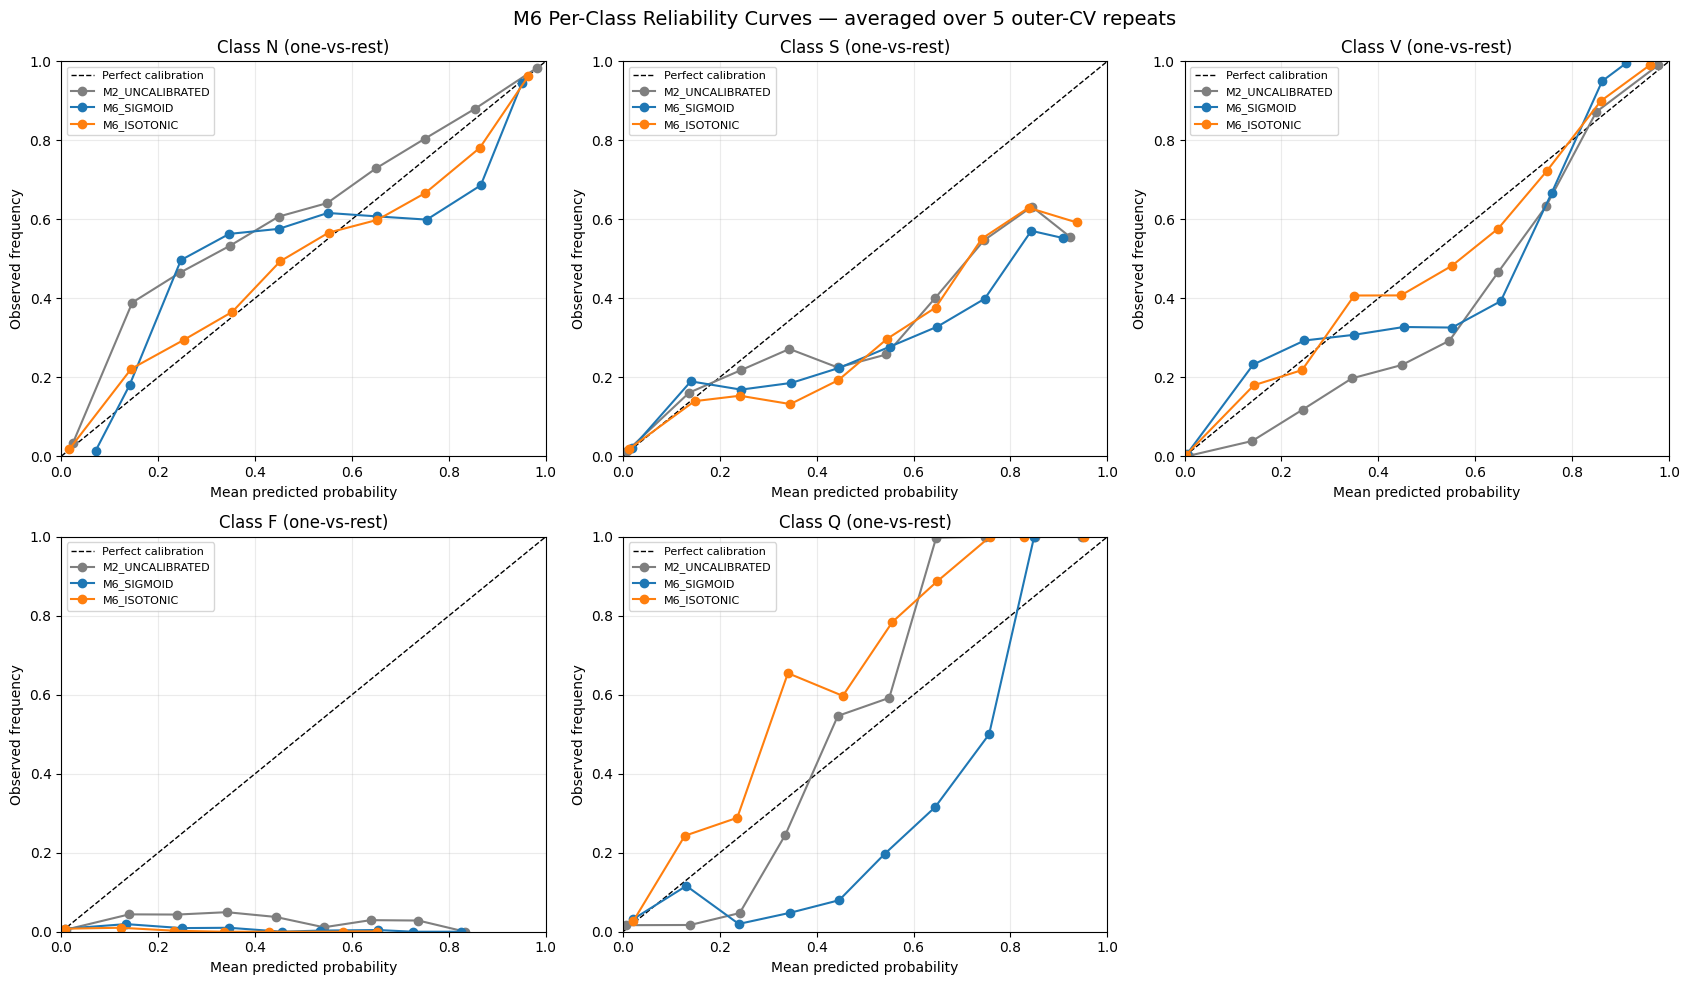

,Experiment,Predicted_Class,Outer_Test_Predictions,Flagged_For_Review,Flag_Rate,Unflagged_Count,Unflagged_Precision
0,M6_SIGMOID,N,95929.0,0.0,0.000000,95929.0,0.922130
1,M6_SIGMOID,S,819.0,811.0,0.988812,8.0,0.825000
2,M6_SIGMOID,V,7860.2,199.4,0.024653,7660.8,0.805627
3,M6_SIGMOID,F,50.2,50.2,1.000000,0.0,NaN
4,M6_SIGMOID,Q,388.6,312.2,0.329325,76.4,0.000000
5,M6_ISOTONIC,N,96995.4,0.0,0.000000,96995.4,0.918816
6,M6_ISOTONIC,S,550.8,467.2,0.913314,83.6,0.561461
7,M6_ISOTONIC,V,7079.4,0.0,0.000000,7079.4,0.843705
8,M6_ISOTONIC,F,2.6,2.6,1.000000,0.0,NaN
9,M6_ISOTONIC,Q,418.8,383.2,0.778151,35.6,0.000000


,Check,Result
0,Corrected_dataset_and_M1_waveforms_verified,PASS
1,105047_valid_beats_and_expected_class_counts,PASS
2,46_records_and_45_people,PASS
3,M0_split_fingerprint_verified,PASS
4,No_new_splits_generated,PASS
5,M2_Version_A_RR_table_missing_counts_verified,PASS
6,17_M2_features_reconstructed,PASS
7,M2_saved_OOF_has_525235_predictions,PASS
8,M2_saved_OOF_uses_locked_outer_folds,PASS
9,M6_all_three_OOF_prediction_sets_complete,PASS


M6 NESTED CALIBRATION COMPLETE — PASS
Output directory: /kaggle/working/ECG_Project/08_M6_PROBABILITY_CALIBRATION


In [7]:
if RUN_M6_CALIBRATION:
    expected_truth = aami_df[["Row_Index", "Record_ID", "Person_ID", "AAMI_Label"]]
    fold_audit_rows = []
    calibration_audit_rows = []
    threshold_rows = []

    for repeat in range(1, N_REPEATS + 1):
        assignment = fold_assignment_by_repeat[repeat]
        for outer_fold in range(1, N_SPLITS + 1):
            fold_pred_path = FOLD_OUTPUT_DIR / f"m6_fold_predictions_repeat_{repeat:02d}_fold_{outer_fold:02d}.csv.gz"
            fold_threshold_path = FOLD_OUTPUT_DIR / f"m6_fold_thresholds_repeat_{repeat:02d}_fold_{outer_fold:02d}.csv"
            fold_cal_audit_path = FOLD_OUTPUT_DIR / f"m6_fold_calibrator_audit_repeat_{repeat:02d}_fold_{outer_fold:02d}.csv"
            fold_audit_path = FOLD_OUTPUT_DIR / f"m6_fold_audit_repeat_{repeat:02d}_fold_{outer_fold:02d}.json"

            # Reuse only a complete, validated checkpoint made by this notebook.
            if fold_pred_path.exists() and fold_threshold_path.exists() and fold_cal_audit_path.exists() and fold_audit_path.exists():
                saved_fold_pred = pd.read_csv(fold_pred_path, compression="infer")
                saved_fold_thresholds = pd.read_csv(fold_threshold_path)
                saved_fold_cal_audit = pd.read_csv(fold_cal_audit_path)
                saved_fold_audit = json.loads(fold_audit_path.read_text())
                expected_val_pos = np.flatnonzero(assignment == outer_fold)
                if len(saved_fold_pred) != len(expected_val_pos) * len(EXPERIMENTS):
                    # A complete fold file contains one row per held-out beat per experiment.
                    raise ValueError(f"Checkpoint has unexpected row count: {fold_pred_path}.")
                if set(saved_fold_pred["Experiment"].unique()) != set(EXPERIMENTS):
                    raise ValueError(f"Checkpoint experiment names mismatch: {fold_pred_path}.")
                fold_pred_parts = [saved_fold_pred]
                threshold_rows.extend(saved_fold_thresholds.to_dict("records"))
                calibration_audit_rows.extend(saved_fold_cal_audit.to_dict("records"))
                fold_audit_rows.append(saved_fold_audit)
                print(f"Loaded completed checkpoint: Repeat {repeat}/{N_REPEATS}, outer fold {outer_fold}/{N_SPLITS}", flush=True)
                continue

            outer_train_pos = np.flatnonzero(assignment != outer_fold)
            outer_test_pos = np.flatnonzero(assignment == outer_fold)
            inner_folds = [f for f in range(1, N_SPLITS + 1) if f != outer_fold]
            if set(person_ids[outer_train_pos]).intersection(set(person_ids[outer_test_pos])):
                raise ValueError("Outer person leakage detected.")
            if set(record_ids[outer_train_pos]).intersection(set(record_ids[outer_test_pos])):
                raise ValueError("Outer record leakage detected.")

            # Build inner OOF probabilities for every outer-training beat.
            inner_oof = np.full((EXPECTED_BEATS, len(CLASS_ORDER)), np.nan, dtype=np.float32)
            inner_fold_sizes = {}
            fold_start = time.time()
            for inner_fold in inner_folds:
                inner_val_pos = np.flatnonzero(assignment == inner_fold)
                inner_train_pos = np.flatnonzero((assignment != outer_fold) & (assignment != inner_fold))
                if not set(person_ids[inner_train_pos]).isdisjoint(set(person_ids[inner_val_pos])):
                    raise ValueError("Inner person leakage detected.")
                if not set(record_ids[inner_train_pos]).isdisjoint(set(record_ids[inner_val_pos])):
                    raise ValueError("Inner record leakage detected.")
                if set(person_ids[inner_train_pos]).intersection(set(person_ids[outer_test_pos])):
                    raise ValueError("Outer-test person entered an inner training fold.")
                if set(person_ids[inner_val_pos]).intersection(set(person_ids[outer_test_pos])):
                    raise ValueError("Outer-test person entered inner calibration predictions.")
                inner_model = make_model()
                inner_model.fit(X[inner_train_pos], y[inner_train_pos])
                inner_prob = to_class_order(inner_model, inner_model.predict_proba(X[inner_val_pos]))
                validate_probability_matrix(inner_prob, f"inner OOF probabilities repeat={repeat}, outer={outer_fold}, inner={inner_fold}")
                inner_oof[inner_val_pos] = inner_prob
                inner_fold_sizes[int(inner_fold)] = {"training_beats": int(len(inner_train_pos)), "validation_beats": int(len(inner_val_pos)), "training_people": int(len(set(person_ids[inner_train_pos]))), "validation_people": int(len(set(person_ids[inner_val_pos])))}
                print(f"M6 inner model complete: repeat {repeat}, outer {outer_fold}, inner {inner_fold}", flush=True)

            if not np.isfinite(inner_oof[outer_train_pos]).all():
                raise ValueError("Some outer-training beats lack inner OOF probabilities.")
            if np.isfinite(inner_oof[outer_test_pos]).any():
                raise ValueError("Outer-test rows must not have inner calibration-training probabilities.")
            inner_train_prob = inner_oof[outer_train_pos]
            inner_train_labels = y[outer_train_pos]
            validate_probability_matrix(inner_train_prob, f"outer training calibration probabilities repeat={repeat}, fold={outer_fold}")

            # Retrieve the raw M2 OOF probabilities for this exact held-out outer fold.
            saved_outer = (
                m2_oof[(m2_oof["Repeat"] == repeat) & (m2_oof["Fold"] == outer_fold)]
                .set_index("Row_Index")
                .loc[row_ids[outer_test_pos]]
            )
            if not np.array_equal(saved_outer["True_Label"].to_numpy(dtype=str), y[outer_test_pos]):
                raise ValueError("M2 outer OOF labels do not align with the held-out rows.")
            outer_raw_prob = saved_outer[PROB_COLS].to_numpy(dtype=np.float32)
            validate_probability_matrix(outer_raw_prob, "M2 outer held-out probabilities")

            # Common metadata for the held-out fold.
            outer_meta = pd.DataFrame({
                "Repeat": repeat,
                "Fold": outer_fold,
                "Row_Index": row_ids[outer_test_pos],
                "Record_ID": record_ids[outer_test_pos],
                "Person_ID": person_ids[outer_test_pos],
                "True_Label": y[outer_test_pos],
            })
            fold_parts = []
            fold_thresholds = []
            fold_cal_audits = []

            # Save the original M2 prediction unchanged as the uncalibrated reference.
            uncal_part = outer_meta.copy()
            uncal_part["Experiment"] = "M2_UNCALIBRATED"
            uncal_part["Predicted_Label"] = saved_outer["Predicted_Label"].to_numpy(dtype=str)
            uncal_part["Confidence"] = outer_raw_prob.max(axis=1)
            uncal_part["Confidence_Threshold"] = np.nan
            uncal_part["Low_Confidence_Flag"] = np.nan
            uncal_part["Threshold_Status"] = "NOT_APPLICABLE_UNCALIBRATED"
            for j, cls in enumerate(CLASS_ORDER):
                uncal_part[f"Prob_{cls}"] = outer_raw_prob[:, j]
            fold_parts.append(uncal_part)

            for exp_name, method in [("M6_SIGMOID", "sigmoid"), ("M6_ISOTONIC", "isotonic")]:
                calibrators, cal_audit = fit_ovr_calibrators(inner_train_prob, inner_train_labels, method)
                for entry in cal_audit:
                    fold_cal_audits.append({"Repeat": repeat, "Outer_Fold": outer_fold, "Experiment": exp_name, **entry})

                # Thresholds are fitted from outer-training inner-OOF predictions only.
                inner_calibrated = apply_ovr_calibrators(inner_train_prob, calibrators, method)
                thresholds, this_threshold_rows = choose_class_thresholds(inner_calibrated, inner_train_labels, exp_name)
                for entry in this_threshold_rows:
                    fold_thresholds.append({"Repeat": repeat, "Outer_Fold": outer_fold, "Experiment": exp_name, **entry})

                outer_calibrated = apply_ovr_calibrators(outer_raw_prob, calibrators, method)
                validate_probability_matrix(outer_calibrated, f"{exp_name} outer predictions")
                cal_part = outer_meta.copy()
                cal_part["Experiment"] = exp_name
                for j, cls in enumerate(CLASS_ORDER):
                    cal_part[f"Prob_{cls}"] = outer_calibrated[:, j]
                flagged = add_confidence_flags(cal_part, outer_calibrated, thresholds)
                fold_parts.append(flagged)

            fold_prediction_df = pd.concat(fold_parts, ignore_index=True)
            atomic_csv(fold_prediction_df, fold_pred_path, index=False, compression="gzip")
            atomic_csv(pd.DataFrame(fold_thresholds), fold_threshold_path, index=False)
            atomic_csv(pd.DataFrame(fold_cal_audits), fold_cal_audit_path, index=False)
            audit = {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "outer_training_beats": int(len(outer_train_pos)),
                "outer_test_beats": int(len(outer_test_pos)),
                "outer_training_people": int(len(set(person_ids[outer_train_pos]))),
                "outer_test_people": int(len(set(person_ids[outer_test_pos]))),
                "inner_folds": inner_fold_sizes,
                "inner_oof_rows": int(len(outer_train_pos)),
                "m2_oof_source": str(m2_oof_path),
                "training_seconds": float(time.time() - fold_start),
                "split_fingerprint": computed_fp,
                "outer_test_people_used_for_calibration_fit": False,
                "outer_test_people_used_for_threshold_fit": False,
            }
            fold_audit_path.write_text(json.dumps(audit, indent=2))
            fold_pred_parts = [fold_prediction_df]
            threshold_rows.extend(fold_thresholds)
            calibration_audit_rows.extend(fold_cal_audits)
            fold_audit_rows.append(audit)
            print(f"M6 completed and checkpointed: repeat {repeat}/{N_REPEATS}, outer fold {outer_fold}/{N_SPLITS}", flush=True)

    # Combine all 25 outer-fold checkpoints.
    checkpoint_files = sorted(FOLD_OUTPUT_DIR.glob("m6_fold_predictions_repeat_*_fold_*.csv.gz"))
    if len(checkpoint_files) != N_REPEATS * N_SPLITS:
        raise ValueError(f"Expected 25 complete fold checkpoints, found {len(checkpoint_files)}.")
    all_fold_frames = [pd.read_csv(p, compression="infer") for p in checkpoint_files]
    all_fold = pd.concat(all_fold_frames, ignore_index=True)
    threshold_files = sorted(FOLD_OUTPUT_DIR.glob("m6_fold_thresholds_repeat_*_fold_*.csv"))
    calibrator_audit_files = sorted(FOLD_OUTPUT_DIR.glob("m6_fold_calibrator_audit_repeat_*_fold_*.csv"))
    audit_files = sorted(FOLD_OUTPUT_DIR.glob("m6_fold_audit_repeat_*_fold_*.json"))
    if len(threshold_files) != 25 or len(calibrator_audit_files) != 25 or len(audit_files) != 25:
        raise ValueError("One or more M6 fold audit/checkpoint files are missing.")
    all_thresholds = pd.concat([pd.read_csv(p) for p in threshold_files], ignore_index=True)
    all_calibration_audit = pd.concat([pd.read_csv(p) for p in calibrator_audit_files], ignore_index=True)
    all_fold_audit = pd.DataFrame([json.loads(p.read_text()) for p in audit_files])

    all_predictions = {}
    for exp_name in EXPERIMENTS:
        exp = all_fold[all_fold["Experiment"] == exp_name].copy()
        exp = exp.sort_values(["Repeat", "Row_Index"]).reset_index(drop=True)
        if len(exp) != EXPECTED_BEATS * N_REPEATS:
            raise ValueError(f"{exp_name}: expected {EXPECTED_BEATS * N_REPEATS} OOF rows, found {len(exp)}.")
        if exp.duplicated(["Repeat", "Row_Index"]).any():
            raise ValueError(f"{exp_name}: duplicate OOF predictions.")
        if not exp.groupby("Repeat")["Row_Index"].nunique().eq(EXPECTED_BEATS).all():
            raise ValueError(f"{exp_name}: one or more repeats lack complete OOF rows.")
        exp = validate_oof(exp, exp_name, aami_df[["Row_Index", "Record_ID", "Person_ID", "AAMI_Label"]], expected_fold_df)
        validate_probability_matrix(exp[PROB_COLS].to_numpy(dtype=float), exp_name)
        all_predictions[exp_name] = exp
        atomic_csv(exp, OUTPUT_DIR / f"m6_oof_predictions_{exp_name}.csv.gz", index=False, compression="gzip")

    atomic_csv(all_thresholds, OUTPUT_DIR / "m6_training_only_thresholds_by_outer_fold.csv", index=False)
    atomic_csv(all_calibration_audit, OUTPUT_DIR / "m6_calibrator_fit_audit.csv", index=False)
    atomic_csv(all_fold_audit, OUTPUT_DIR / "m6_nested_fold_audit.csv", index=False)

    # Confirm the uncalibrated M6 output is the saved M2 OOF output, row for row.
    uncal = all_predictions["M2_UNCALIBRATED"]
    compare = uncal.merge(
        m2_oof[["Repeat", "Row_Index", "Predicted_Label"] + PROB_COLS],
        on=["Repeat", "Row_Index"], how="inner", suffixes=("_m6", "_m2"), validate="one_to_one"
    )
    if len(compare) != EXPECTED_BEATS * N_REPEATS:
        raise ValueError("M6 uncalibrated output does not align with all saved M2 OOF predictions.")
    uncal_label_agreement = float((compare["Predicted_Label_m6"] == compare["Predicted_Label_m2"]).mean())
    uncal_max_probability_difference = float(np.abs(
        compare[[f"{c}_m6" for c in PROB_COLS]].to_numpy(dtype=float)
        - compare[[f"{c}_m2" for c in PROB_COLS]].to_numpy(dtype=float)
    ).max())
    if uncal_label_agreement != 1.0 or uncal_max_probability_difference > 1e-6:
        raise AssertionError("M6 uncalibrated output does not reproduce the saved M2 OOF predictions.")
    print("M2 UNCALIBRATED OOF REPRODUCTION — PASS")
    print("Label agreement:", f"{uncal_label_agreement:.6f}", "| max probability difference:", f"{uncal_max_probability_difference:.8f}")

    # %%
    # Classification metrics: pool predictions within each repeat, then average over repeats.
    repeat_metric_frames = []
    class_metric_frames = []
    confusion_frames = []
    calibration_metric_frames = []
    reliability_curve_frames = []
    for exp_name, pred_df in all_predictions.items():
        repeat_df, class_df, confusion_df, cal_df, curve_df = calculate_repeat_metrics(pred_df, exp_name)
        repeat_metric_frames.append(repeat_df)
        class_metric_frames.append(class_df)
        confusion_frames.append(confusion_df)
        calibration_metric_frames.append(cal_df)
        reliability_curve_frames.append(curve_df)
        atomic_csv(repeat_df, OUTPUT_DIR / f"m6_repeat_classification_metrics_{exp_name}.csv", index=False)
        atomic_csv(class_df, OUTPUT_DIR / f"m6_per_class_classification_metrics_{exp_name}.csv", index=False)
        atomic_csv(confusion_df, OUTPUT_DIR / f"m6_confusion_matrices_{exp_name}.csv", index=False)

    repeat_metrics = pd.concat(repeat_metric_frames, ignore_index=True)
    per_class_metrics = pd.concat(class_metric_frames, ignore_index=True)
    confusion_matrices = pd.concat(confusion_frames, ignore_index=True)
    calibration_metrics_by_repeat = pd.concat(calibration_metric_frames, ignore_index=True)
    reliability_curves = pd.concat(reliability_curve_frames, ignore_index=True)
    atomic_csv(repeat_metrics, OUTPUT_DIR / "m6_classification_metrics_by_repeat.csv", index=False)
    atomic_csv(per_class_metrics, OUTPUT_DIR / "m6_classification_per_class_by_repeat.csv", index=False)
    atomic_csv(confusion_matrices, OUTPUT_DIR / "m6_confusion_matrices_all_experiments.csv", index=False)
    atomic_csv(calibration_metrics_by_repeat, OUTPUT_DIR / "m6_calibration_metrics_by_repeat.csv", index=False)
    atomic_csv(reliability_curves, OUTPUT_DIR / "m6_reliability_curve_points_by_repeat.csv", index=False)

    classification_headline = (
        repeat_metrics.groupby("Experiment", sort=False)[["Macro_F1_5_Class", "Macro_F1_4_Class_N_S_V_Q", "Balanced_Accuracy", "Accuracy"]]
        .mean().reset_index()
    )
    calibration_headline = (
        calibration_metrics_by_repeat[calibration_metrics_by_repeat["Class"] == "__OVERALL__"]
        .groupby("Experiment", sort=False)[["Log_Loss", "Brier_Score", "Macro_Class_Brier", "Macro_Class_ECE", "ECE_10_Bins"]]
        .mean().reset_index()
        .rename(columns={"ECE_10_Bins": "Top_Label_ECE_10_Bins"})
    )
    headline = classification_headline.merge(calibration_headline, on="Experiment", how="left")
    display(headline)
    atomic_csv(headline, OUTPUT_DIR / "m6_headline_results.csv", index=False)

    per_class_calibration = (
        calibration_metrics_by_repeat[calibration_metrics_by_repeat["Class"] != "__OVERALL__"]
        .groupby(["Experiment", "Class"], sort=False)[["Brier_Score", "ECE_10_Bins"]]
        .mean().reset_index()
    )
    display(per_class_calibration)
    atomic_csv(per_class_calibration, OUTPUT_DIR / "m6_per_class_calibration_metrics.csv", index=False)

    # Record-level bootstrap CIs for calibration quality metrics.
    # Sufficient statistics are aggregated per (repeat, record, bin), avoiding beat-level resampling.
    def _build_record_calibration_stats(pred_df):
        record_order = sorted(pred_df["Record_ID"].unique().tolist())
        record_pos = {rid: i for i, rid in enumerate(record_order)}
        R, NREC, K, B = N_REPEATS, len(record_order), len(CLASS_ORDER), N_CALIBRATION_BINS
        n_stats = np.zeros((R, NREC), dtype=np.float64)
        logloss_stats = np.zeros((R, NREC), dtype=np.float64)
        brier_stats = np.zeros((R, NREC), dtype=np.float64)
        class_bin_stats = np.zeros((R, NREC, K, B, 3), dtype=np.float64)  # n, sum(p), sum(y)
        top_bin_stats = np.zeros((R, NREC, B, 3), dtype=np.float64)        # n, sum(conf), sum(correct)
        for rep in range(1, R + 1):
            part = pred_df[pred_df["Repeat"] == rep]
            p_all = part[PROB_COLS].to_numpy(dtype=float)
            labels = part["True_Label"].to_numpy(dtype=str)
            true_idx = np.array([CLASS_ORDER.index(v) for v in labels], dtype=int)
            pred_idx = np.argmax(p_all, axis=1)
            confidence = p_all.max(axis=1)
            correct = (pred_idx == true_idx).astype(float)
            ll = -np.log(np.clip(p_all[np.arange(len(part)), true_idx], 1e-15, 1.0))
            one_hot = np.eye(K, dtype=float)[true_idx]
            br = np.square(p_all - one_hot).sum(axis=1)
            rec_vals = part["Record_ID"].to_numpy(dtype=int)
            for rid in record_order:
                idx = np.flatnonzero(rec_vals == rid)
                if not len(idx):
                    continue
                ri = record_pos[rid]
                n_stats[rep - 1, ri] = len(idx)
                logloss_stats[rep - 1, ri] = ll[idx].sum()
                brier_stats[rep - 1, ri] = br[idx].sum()
                top_bins = equal_width_bin_ids(confidence[idx])
                for b in range(B):
                    m = top_bins == b
                    if m.any():
                        top_bin_stats[rep - 1, ri, b, 0] = int(m.sum())
                        top_bin_stats[rep - 1, ri, b, 1] = confidence[idx][m].sum()
                        top_bin_stats[rep - 1, ri, b, 2] = correct[idx][m].sum()
                for k in range(K):
                    p = p_all[idx, k]
                    yy = (labels[idx] == CLASS_ORDER[k]).astype(float)
                    bins = equal_width_bin_ids(p)
                    for b in range(B):
                        m = bins == b
                        if m.any():
                            class_bin_stats[rep - 1, ri, k, b, 0] = int(m.sum())
                            class_bin_stats[rep - 1, ri, k, b, 1] = p[m].sum()
                            class_bin_stats[rep - 1, ri, k, b, 2] = yy[m].sum()
        return record_order, n_stats, logloss_stats, brier_stats, class_bin_stats, top_bin_stats

    def _ece_from_stats(stats):
        # stats has final dimensions [bin, (count, sum_probability, sum_observed)].
        n = stats[..., 0]
        sum_p = stats[..., 1]
        sum_y = stats[..., 2]
        total = n.sum(axis=-1)
        valid = n > 0
        mean_p = np.divide(sum_p, n, out=np.zeros_like(sum_p), where=valid)
        mean_y = np.divide(sum_y, n, out=np.zeros_like(sum_y), where=valid)
        ece = np.sum(np.where(valid, n * np.abs(mean_p - mean_y), 0.0), axis=-1) / np.maximum(total, 1.0)
        return ece

    def record_bootstrap_calibration_ci(pred_df, experiment_name, record_order, stats, rng):
        _, n_stats, logloss_stats, brier_stats, class_bin_stats, top_bin_stats = stats
        values = {"Log_Loss": [], "Multiclass_Brier": [], "Macro_Classwise_ECE": [], "Top_Label_ECE": []}
        n_records = len(record_order)
        for _ in range(BOOTSTRAP_SAMPLES):
            sampled = rng.integers(0, n_records, size=n_records)
            per_repeat = {k: [] for k in values}
            for ri in range(N_REPEATS):
                n = float(n_stats[ri, sampled].sum())
                if n <= 0:
                    continue
                per_repeat["Log_Loss"].append(float(logloss_stats[ri, sampled].sum() / n))
                per_repeat["Multiclass_Brier"].append(float(brier_stats[ri, sampled].sum() / n))
                cstats = class_bin_stats[ri, sampled].sum(axis=0)  # K x B x 3
                class_eces = _ece_from_stats(cstats)
                per_repeat["Macro_Classwise_ECE"].append(float(np.mean(class_eces)))
                tstats = top_bin_stats[ri, sampled].sum(axis=0)  # B x 3
                per_repeat["Top_Label_ECE"].append(float(_ece_from_stats(tstats)))
            for key in values:
                values[key].append(float(np.mean(per_repeat[key])))
        rows = []
        for metric, samples in values.items():
            point_by_repeat = []
            for rep in range(1, N_REPEATS + 1):
                one = pred_df[pred_df["Repeat"] == rep]
                probs = one[PROB_COLS].to_numpy(dtype=float)
                labels = one["True_Label"].to_numpy(dtype=str)
                if metric == "Log_Loss":
                    idx = np.array([CLASS_ORDER.index(v) for v in labels], dtype=int)
                    point_by_repeat.append(float(-np.log(np.clip(probs[np.arange(len(one)), idx], 1e-15, 1.0)).mean()))
                elif metric == "Multiclass_Brier":
                    idx = np.array([CLASS_ORDER.index(v) for v in labels], dtype=int)
                    oh = np.eye(len(CLASS_ORDER), dtype=float)[idx]
                    point_by_repeat.append(float(np.square(probs - oh).sum(axis=1).mean()))
                elif metric == "Macro_Classwise_ECE":
                    _, _, _, ece = classwise_calibration_table(probs, labels, experiment_name, rep)
                    point_by_repeat.append(float(ece))
                else:
                    point_by_repeat.append(top_label_ece(probs, labels))
            lower, upper = np.quantile(np.asarray(samples, dtype=float), [0.025, 0.975])
            rows.append({
                "Experiment": experiment_name,
                "Metric": metric,
                "Point_Estimate": float(np.mean(point_by_repeat)),
                "CI_95_Lower": float(lower),
                "CI_95_Upper": float(upper),
                "Bootstrap_Samples": BOOTSTRAP_SAMPLES,
                "Resampling_Unit": "Record_ID",
                "Bootstrap_Seed": BOOTSTRAP_SEED,
            })
        return rows

    bootstrap_rows = []
    for exp_name, pred_df in all_predictions.items():
        stats = _build_record_calibration_stats(pred_df)
        # Reset the seed so each experiment uses the same record-resampling draws.
        bootstrap_rng = np.random.default_rng(BOOTSTRAP_SEED)
        bootstrap_rows.extend(record_bootstrap_calibration_ci(pred_df, exp_name, stats[0], stats, bootstrap_rng))
    calibration_bootstrap_ci = pd.DataFrame(bootstrap_rows)
    display(calibration_bootstrap_ci)
    atomic_csv(calibration_bootstrap_ci, OUTPUT_DIR / "m6_record_level_calibration_bootstrap_ci.csv", index=False)

    # Mean reliability points over repeats, preserving the same 10 equal-width bins in each repeat.
    curve_summary = (
        reliability_curves.groupby(["Experiment", "Class", "Bin", "Bin_Lower", "Bin_Upper"], sort=False)
        .agg(Mean_Predicted_Probability=("Mean_Predicted_Probability", "mean"),
             Observed_Frequency=("Observed_Frequency", "mean"),
             Mean_Count=("Count", "mean"),
             Repeats_With_Observations=("Repeat", "nunique"))
        .reset_index()
    )
    atomic_csv(curve_summary, OUTPUT_DIR / "m6_reliability_curve_summary.csv", index=False)

    # One reliability chart with a panel for each class and three experiment curves.
    fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    axes = axes.ravel()
    colors = {"M2_UNCALIBRATED": "tab:gray", "M6_SIGMOID": "tab:blue", "M6_ISOTONIC": "tab:orange"}
    for j, cls in enumerate(CLASS_ORDER):
        ax = axes[j]
        ax.plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=1, label="Perfect calibration")
        for exp_name in EXPERIMENTS:
            sub = curve_summary[(curve_summary["Experiment"] == exp_name) & (curve_summary["Class"] == cls) & (curve_summary["Repeats_With_Observations"] > 0)]
            ax.plot(sub["Mean_Predicted_Probability"], sub["Observed_Frequency"], marker="o", linewidth=1.5, label=exp_name, color=colors[exp_name])
        ax.set_title(f"Class {cls} (one-vs-rest)")
        ax.set_xlabel("Mean predicted probability")
        ax.set_ylabel("Observed frequency")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    axes[5].axis("off")
    fig.suptitle("M6 Per-Class Reliability Curves — averaged over 5 outer-CV repeats", fontsize=14)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "m6_per_class_reliability_curves.png", dpi=160, bbox_inches="tight")
    plt.show()

    # Evaluate the fold-specific training-only thresholds on their outer held-out beats.
    threshold_eval_rows = []
    for exp_name in ["M6_SIGMOID", "M6_ISOTONIC"]:
        pred_df = all_predictions[exp_name]
        for repeat in range(1, N_REPEATS + 1):
            part = pred_df[pred_df["Repeat"] == repeat]
            for cls in CLASS_ORDER:
                predicted_as = part[part["Predicted_Label"] == cls]
                n_predicted = len(predicted_as)
                if n_predicted:
                    flagged = predicted_as["Low_Confidence_Flag"].astype(bool)
                    unflagged = predicted_as[~flagged]
                    unflagged_precision = float((unflagged["Predicted_Label"] == unflagged["True_Label"]).mean()) if len(unflagged) else np.nan
                    flagged_count = int(flagged.sum())
                else:
                    flagged_count = 0
                    unflagged_precision = np.nan
                threshold_eval_rows.append({
                    "Experiment": exp_name,
                    "Repeat": repeat,
                    "Predicted_Class": cls,
                    "Outer_Test_Predictions": n_predicted,
                    "Flagged_For_Review": flagged_count,
                    "Flag_Rate": (flagged_count / n_predicted) if n_predicted else np.nan,
                    "Unflagged_Count": n_predicted - flagged_count,
                    "Unflagged_Precision": unflagged_precision,
                    "Target_Precision": TARGET_HIGH_CONFIDENCE_PRECISION,
                })
    threshold_evaluation = pd.DataFrame(threshold_eval_rows)
    display(threshold_evaluation.groupby(["Experiment", "Predicted_Class"], sort=False)[["Outer_Test_Predictions", "Flagged_For_Review", "Flag_Rate", "Unflagged_Count", "Unflagged_Precision"]].mean().reset_index())
    atomic_csv(threshold_evaluation, OUTPUT_DIR / "m6_low_confidence_threshold_outer_test_evaluation_by_repeat.csv", index=False)

    threshold_summary = (
        all_thresholds.groupby(["Experiment", "Class", "Status"], sort=False)
        .agg(Median_Threshold=("Threshold", "median"), Mean_Threshold=("Threshold", "mean"),
             Outer_Folds=("Outer_Fold", "nunique"),
             Median_Training_Unflagged_Precision=("Training_Unflagged_Precision", "median"),
             Median_Training_Unflagged_Count=("Training_Unflagged_Count_At_Threshold", "median"))
        .reset_index()
    )
    atomic_csv(threshold_summary, OUTPUT_DIR / "m6_low_confidence_threshold_summary.csv", index=False)

    checks = {
        "Corrected_dataset_and_M1_waveforms_verified": True,
        "105047_valid_beats_and_expected_class_counts": len(aami_df) == EXPECTED_BEATS and counts == EXPECTED_COUNTS,
        "46_records_and_45_people": aami_df.Record_ID.nunique() == EXPECTED_RECORDS and aami_df.Person_ID.nunique() == EXPECTED_PEOPLE,
        "M0_split_fingerprint_verified": computed_fp == EXPECTED_SPLIT_FINGERPRINT,
        "No_new_splits_generated": True,
        "M2_Version_A_RR_table_missing_counts_verified": observed_missing == EXPECTED_RR_MISSING and observed_rows_missing == EXPECTED_ROWS_WITH_MISSING_RR,
        "17_M2_features_reconstructed": X.shape == (EXPECTED_BEATS, 17),
        "M2_saved_OOF_has_525235_predictions": len(m2_oof) == EXPECTED_BEATS * N_REPEATS,
        "M2_saved_OOF_uses_locked_outer_folds": True,
        "M6_all_three_OOF_prediction_sets_complete": all(len(v) == EXPECTED_BEATS * N_REPEATS for v in all_predictions.values()),
        "M6_outer_fold_people_excluded_from_calibration_and_threshold_fitting": bool((all_fold_audit["outer_test_people_used_for_calibration_fit"] == False).all() and (all_fold_audit["outer_test_people_used_for_threshold_fit"] == False).all()),
        "M2_uncalibrated_OOF_reproduced": uncal_label_agreement == 1.0 and uncal_max_probability_difference <= 1e-6,
        "All_calibrated_probabilities_sum_to_one": all(np.allclose(v[PROB_COLS].sum(axis=1), 1.0, atol=1e-5) for k, v in all_predictions.items()),
        "All_25_outer_folds_completed": len(all_fold_audit) == N_REPEATS * N_SPLITS,
    }
    check_table = pd.DataFrame([{"Check": k, "Result": "PASS" if v else "FAIL"} for k, v in checks.items()])
    display(check_table)
    atomic_csv(check_table, OUTPUT_DIR / "m6_final_validation_checks.csv", index=False)
    if not all(checks.values()):
        raise AssertionError("M6 final validation failed. STOP.")

    manifest = {
        "phase": "M6 — PROBABILITY CALIBRATION",
        "base_model": "M2 Version A unweighted RandomForestClassifier",
        "base_features": FEATURE_NAMES,
        "feature_count": 17,
        "base_model_settings": {"n_estimators": TREES, "max_features": MAX_FEATURES, "class_weight": None, "random_state": SEED, "n_jobs": -1},
        "calibration_methods": ["sigmoid (one-vs-rest)", "isotonic (one-vs-rest)"],
        "nested_design": "5 saved M0 repeats x 5 outer folds; for each outer fold, 4 inner OOF folds within outer training only; saved M2 OOF probabilities supply the outer held-out base probabilities",
        "threshold_rule": "For N/S/V/Q, choose the lowest 0.01-grid threshold meeting training-only predicted-class precision target with minimum support; otherwise threshold=1.01 and all predictions of that class are flagged. F is always flagged as not supported / experimental.",
        "target_high_confidence_precision": TARGET_HIGH_CONFIDENCE_PRECISION,
        "minimum_threshold_support": MIN_THRESHOLD_SUPPORT,
        "threshold_grid": [float(THRESHOLD_GRID.min()), float(THRESHOLD_GRID.max()), 0.01],
        "low_confidence_threshold_is_clinical": False,
        "valid_beats": EXPECTED_BEATS,
        "records": EXPECTED_RECORDS,
        "people": EXPECTED_PEOPLE,
        "m2_rr_table": str(rr_path),
        "m2_oof_predictions": str(m2_oof_path),
        "split_fingerprint": computed_fp,
        "splits_regenerated": False,
        "bootstrap_samples": BOOTSTRAP_SAMPLES,
        "bootstrap_seed": BOOTSTRAP_SEED,
        "bootstrap_unit": "Record_ID",
        "python": sys.version,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
    }
    (OUTPUT_DIR / "m6_manifest.json").write_text(json.dumps(manifest, indent=2))
    (OUTPUT_DIR / "M6_DECISION_NOTE.txt").write_text(
        "M6 evaluates sigmoid and isotonic calibration using nested, person-grouped outer folds.\n"
        "Do not select a calibration method solely from the same outer OOF results and then report those results as an untouched final test.\n"
        "Use M6 outputs to document calibration behaviour and choose a provisional deployment method.\n"
        "M7 must fit the final base model and calibrator on development data only, then evaluate once on an untouched demo-person set if one has been designated.\n"
        "The configured 0.80 predicted-class precision target is a project policy default, not a clinical threshold; approve it before app use.\n"
    )
    print("M6 NESTED CALIBRATION COMPLETE — PASS")
    print("Output directory:", OUTPUT_DIR)
else:
    print("M6 training skipped because RUN_M6_CALIBRATION=False.")
    print("After all validation checks pass, set RUN_M6_CALIBRATION=True and Save Version → Save & Run All (Commit).")